# High-risk long QQQ / short AI equal-weight portfolio backtest

This notebook tests a pre-specified intraday strategy:

- **Signal:** at the start of target hour $t$, use only `AI_Risk_total` from $[t-1,t)$.
- **High risk:** the lagged value is strictly above the expanding 75th percentile of earlier observed-eligible risk values. The threshold excludes the signal observation itself and requires at least 72 earlier eligible hours.
- **Position when high:** long 50% QQQ and short 50% of the fixed 20-stock AI equal-weight basket. Otherwise hold cash.
- **Return window:** New York 10:00–11:00 through 15:00–16:00 only. There is no overnight return.
- **Costs:** main net result charges 5 bps per one-way unit of gross turnover. Positions are forced flat after each trading day's last bar.

QQQ is a liquid proxy for the Nasdaq-100, not the Nasdaq Composite. The 50/50 construction has 100% gross exposure. The raw spread `QQQ - AI` is also retained and corresponds to a $1 long / $1 short, or 200% gross, convention.

This is a short historical backtest on the observed X News sample. It is not evidence of structural causality and does not include borrow fees, bid–ask variation, market impact, processing latency beyond the one-hour lag, or tax effects.

In [1]:
from pathlib import Path
import platform
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import statsmodels
import statsmodels.api as sm
from IPython.display import Markdown, display
from scipy import stats

warnings.filterwarnings("default")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 190)
pd.set_option("display.float_format", lambda value: f"{value:,.6g}")

ROOT = Path.cwd().resolve()
if not (ROOT / "download_hourly_returns.py").exists():
    raise RuntimeError("Run this notebook from the project root directory.")

AI_PATH = ROOT / "data" / "hourly_10_16" / "hourly_returns_long.csv"
QQQ_PATH = ROOT / "data" / "qqq_hourly_10_16" / "hourly_returns_long.csv"
RISK_PATH = ROOT / "data" / "hourly_ai_risk_index" / "x" / "hourly_ai_risk_index.csv"
for path in (AI_PATH, QQQ_PATH, RISK_PATH):
    if not path.exists():
        raise FileNotFoundError(path)

environment = pd.DataFrame(
    {
        "component": ["Python", "pandas", "NumPy", "SciPy", "statsmodels", "matplotlib", "platform"],
        "version": [
            platform.python_version(), pd.__version__, np.__version__, scipy.__version__,
            statsmodels.__version__, plt.matplotlib.__version__, platform.platform(),
        ],
    }
)
display(environment)
print("Interpreter:", sys.executable)
print("Project root:", ROOT)

,component,version
0,Python,3.14.7
1,pandas,3.0.6
2,NumPy,2.5.3
3,SciPy,1.18.1
4,statsmodels,0.15.0
5,matplotlib,3.11.2
6,platform,Windows-11-10.0.26200-SP0


Interpreter: C:\Users\Jerry Cai\Desktop\NLP_Assignment4_AI_risk_and_AI_development\.venv\Scripts\python.exe
Project root: C:\Users\Jerry Cai\Desktop\NLP_Assignment4_AI_risk_and_AI_development


## 1. Load and validate QQQ and the fixed 20-stock basket

In [2]:
AI_TICKERS = (
    "MSFT", "GOOGL", "META", "AMZN", "TSLA", "ORCL", "CRM", "NOW", "ADBE", "WDAY",
    "INTU", "PATH", "AAPL", "PLTR", "UBER", "SNOW", "SHOP", "RBLX", "SNAP", "PINS",
)


def parse_bool(series: pd.Series) -> pd.Series:
    return series.astype(str).str.strip().str.lower().eq("true")


def load_returns(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    required = {
        "ticker", "trading_date", "bar_start_utc", "bar_end_utc", "duration_minutes",
        "window_complete", "ohlc_valid", "nonpositive_price",
        "split_event", "return_requires_review", "ret_oc", "source", "feed", "adjustment",
    }
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {sorted(missing)}")
    frame["bar_start_utc"] = pd.to_datetime(frame["bar_start_utc"], utc=True)
    frame["bar_end_utc"] = pd.to_datetime(frame["bar_end_utc"], utc=True)
    for column in (
        "window_complete", "ohlc_valid", "nonpositive_price", "split_event", "return_requires_review"
    ):
        frame[column] = parse_bool(frame[column])
    frame["duration_minutes"] = pd.to_numeric(frame["duration_minutes"], errors="coerce")
    frame["ret_oc"] = pd.to_numeric(frame["ret_oc"], errors="coerce")
    if "window_mode" in frame.columns and set(frame["window_mode"].dropna().unique()) != {"clock_10_16"}:
        raise ValueError(f"Unexpected window mode in {path}")
    if not frame["duration_minutes"].eq(60).all():
        raise ValueError(f"Non-60-minute window in {path}")
    if frame.duplicated(["ticker", "bar_start_utc"]).any():
        raise ValueError(f"Duplicate ticker/timestamp in {path}")
    return frame


ai_raw = load_returns(AI_PATH)
qqq_raw = load_returns(QQQ_PATH)
if set(ai_raw["ticker"].unique()) != set(AI_TICKERS):
    raise ValueError("AI ticker pool does not exactly match the requested fixed 20 stocks")
if set(qqq_raw["ticker"].unique()) != {"QQQ"}:
    raise ValueError("Benchmark file must contain only QQQ")


def usable_mask(frame: pd.DataFrame) -> pd.Series:
    return (
        frame["window_complete"]
        & frame["ohlc_valid"]
        & ~frame["nonpositive_price"]
        & ~frame["split_event"]
        & ~frame["return_requires_review"]
        & frame["ret_oc"].notna()
    )


ai_raw["usable"] = usable_mask(ai_raw)
ai_rows = []
keys = ["trading_date", "bar_start_utc", "bar_end_utc"]
for (trading_date, bar_start, bar_end), group in ai_raw.groupby(keys, sort=True):
    usable = group.loc[group["usable"]]
    complete = set(usable["ticker"]) == set(AI_TICKERS) and len(usable) == len(AI_TICKERS)
    ai_rows.append(
        {
            "trading_date": str(trading_date),
            "bar_start_utc": bar_start,
            "bar_end_utc": bar_end,
            "ai_constituents": int(usable["ticker"].nunique()),
            "ai_all_20_valid": bool(complete),
            "ai_ew_ret_oc": float(usable["ret_oc"].mean()) if complete else np.nan,
        }
    )
ai_hourly = pd.DataFrame(ai_rows)
if not ai_hourly["ai_all_20_valid"].all():
    raise ValueError("At least one AI basket hour does not contain all 20 valid constituents")

AI_RETURN_COLUMNS = [f"ai_ret_{ticker}" for ticker in AI_TICKERS]
ai_return_wide = (
    ai_raw.loc[ai_raw["usable"]]
    .pivot(index=keys, columns="ticker", values="ret_oc")
    .reset_index()
    .rename_axis(columns=None)
    .rename(columns={ticker: f"ai_ret_{ticker}" for ticker in AI_TICKERS})
)
if ai_return_wide[AI_RETURN_COLUMNS].isna().any().any():
    raise ValueError("Wide AI constituent return grid contains missing values")

qqq_hourly = qqq_raw.loc[usable_mask(qqq_raw), keys + ["ret_oc"]].copy()
qqq_hourly["trading_date"] = qqq_hourly["trading_date"].astype(str)
qqq_hourly = qqq_hourly.rename(columns={"ret_oc": "qqq_ret_oc"})
if len(qqq_hourly) != len(qqq_raw):
    raise ValueError("At least one QQQ hour failed the quality filter")

market = ai_hourly.merge(qqq_hourly, on=keys, how="inner", validate="one_to_one")
market = market.merge(ai_return_wide, on=keys, how="inner", validate="one_to_one")
if len(market) != len(ai_hourly) or len(market) != len(qqq_hourly):
    raise ValueError("QQQ and AI basket hours do not align one-to-one")
ASSET_RETURN_COLUMNS = ["qqq_ret_oc", *AI_RETURN_COLUMNS]
market = market.sort_values("bar_start_utc").reset_index(drop=True)
market["bar_start_ny"] = market["bar_start_utc"].dt.tz_convert("America/New_York")
market["bar_end_ny"] = market["bar_end_utc"].dt.tz_convert("America/New_York")
market["target_hour"] = market["bar_start_ny"].dt.hour.astype(str).str.zfill(2) + ":00"
market["weekday"] = pd.to_datetime(market["trading_date"]).dt.day_name()
if set(market["bar_start_ny"].dt.hour.unique()) != set(range(10, 16)):
    raise ValueError("Expected target starts from 10:00 through 15:00 New York")
if not (market["bar_end_utc"] - market["bar_start_utc"]).eq(pd.Timedelta(hours=1)).all():
    raise ValueError("Market windows are not exactly one hour")

source_check = pd.concat(
    [
        ai_raw[["source", "feed", "adjustment"]].drop_duplicates().assign(dataset="AI basket"),
        qqq_raw[["source", "feed", "adjustment"]].drop_duplicates().assign(dataset="QQQ"),
    ],
    ignore_index=True,
)
audit = pd.DataFrame(
    {
        "check": [
            "AI tickers", "AI hourly windows", "AI windows with all 20", "QQQ hourly windows",
            "aligned windows", "trading days", "first target start NY", "last target end NY",
        ],
        "value": [
            len(AI_TICKERS), len(ai_hourly), int(ai_hourly["ai_all_20_valid"].sum()), len(qqq_hourly),
            len(market), market["trading_date"].nunique(), str(market["bar_start_ny"].min()),
            str(market["bar_end_ny"].max()),
        ],
    }
)
display(audit)
display(Markdown("### Source and adjustment check"))
display(source_check)

,check,value
0,AI tickers,20
1,AI hourly windows,138
2,AI windows with all 20,138
3,QQQ hourly windows,138
4,aligned windows,138
5,trading days,23
6,first target start NY,2026-09-01 10:00:00-04:00
7,last target end NY,2026-10-02 16:00:00-04:00


### Source and adjustment check

,source,feed,adjustment,dataset
0,yahoo,yahoo_consolidated,raw_unadjusted_auto_adjust_false,AI basket
1,yahoo,yahoo_consolidated,raw_unadjusted_auto_adjust_false,QQQ


## 2. Construct the strictly lagged high-risk signal

,check,value
0,risk hourly rows,723
1,observed-eligible risk hours,622
2,strict-eligible risk hours,0
3,minimum prior eligible hours,72
4,threshold-available timeline hours,108
5,signal-ready market hours,100
6,signal-missing timeline hours,8
7,signal-ready trading days,18
8,high-risk hours,31
9,high-risk trading days,14


### Exact no-look-ahead example

,item,start_NY,end_NY,value
0,risk window,2026-09-08 11:00:00-04:00,2026-09-08 12:00:00-04:00,0.198305
1,target return window,2026-09-08 12:00:00-04:00,2026-09-08 13:00:00-04:00,NaN


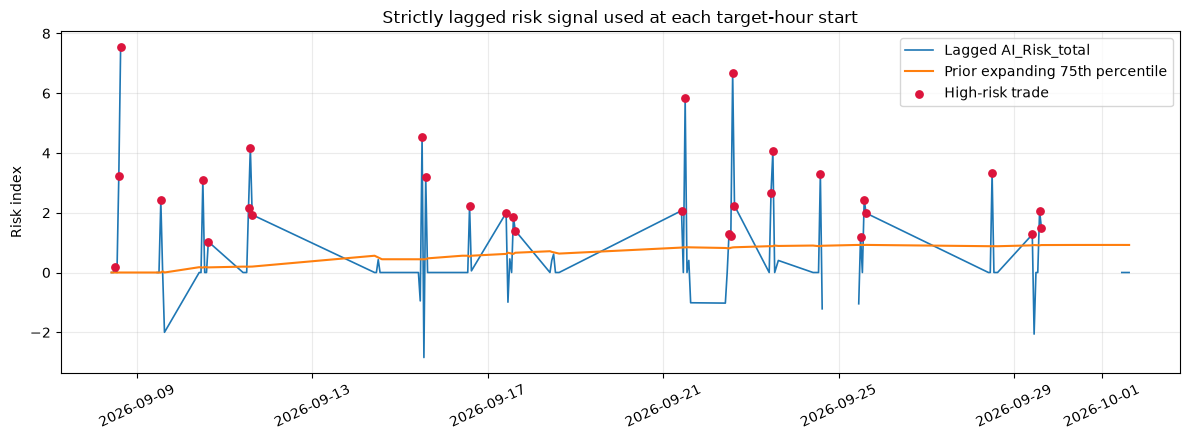

In [3]:
PRIMARY_QUANTILE = 0.75
MIN_PRIOR_RISK_HOURS = 72

risk = pd.read_csv(RISK_PATH)
risk_required = {
    "hour", "AI_Risk_total", "is_backtest_eligible_observed_sample",
    "is_backtest_eligible_strict", "queries_at_result_cap",
}
missing = risk_required.difference(risk.columns)
if missing:
    raise ValueError(f"Risk file is missing columns: {sorted(missing)}")
risk["hour"] = pd.to_datetime(risk["hour"], utc=True)
risk["AI_Risk_total"] = pd.to_numeric(risk["AI_Risk_total"], errors="coerce")
risk["observed_eligible"] = parse_bool(risk["is_backtest_eligible_observed_sample"])
risk["strict_eligible"] = parse_bool(risk["is_backtest_eligible_strict"])
risk = risk.sort_values("hour").reset_index(drop=True)
if risk["hour"].duplicated().any():
    raise ValueError("Duplicate risk timestamps")
if not risk["hour"].diff().dropna().eq(pd.Timedelta(hours=1)).all():
    raise ValueError("Risk file is not a continuous hourly grid")

risk["eligible_risk"] = risk["AI_Risk_total"].where(risk["observed_eligible"])
# At risk hour h, this threshold uses eligible observations no later than h-1.
risk["prior_q75"] = (
    risk["eligible_risk"].shift(1).expanding(min_periods=MIN_PRIOR_RISK_HOURS).quantile(PRIMARY_QUANTILE)
)
signal_table = risk[["hour", "eligible_risk", "prior_q75"]].rename(columns={"hour": "risk_hour"})

market["risk_hour"] = market["bar_start_utc"] - pd.Timedelta(hours=1)
market = market.merge(signal_table, on="risk_hour", how="left", validate="many_to_one")
market["signal_ready"] = market["eligible_risk"].notna() & market["prior_q75"].notna()
market["high_risk"] = market["signal_ready"] & market["eligible_risk"].gt(market["prior_q75"])
market["threshold_available"] = market["prior_q75"].notna()
market["signal_missing"] = market["threshold_available"] & ~market["signal_ready"]
if not (market["risk_hour"] + pd.Timedelta(hours=1)).eq(market["bar_start_utc"]).all():
    raise AssertionError("Risk signal is not exactly one hour behind the return window")

backtest = market.loc[market["threshold_available"]].copy().reset_index(drop=True)
if backtest.empty:
    raise ValueError("No threshold-available backtest observations")

signal_audit = pd.DataFrame(
    {
        "check": [
            "risk hourly rows", "observed-eligible risk hours", "strict-eligible risk hours",
            "minimum prior eligible hours", "threshold-available timeline hours",
            "signal-ready market hours", "signal-missing timeline hours", "signal-ready trading days",
            "high-risk hours", "high-risk trading days", "first signal-ready target", "last signal-ready target",
        ],
        "value": [
            len(risk), int(risk["observed_eligible"].sum()), int(risk["strict_eligible"].sum()),
            MIN_PRIOR_RISK_HOURS, len(backtest), int(backtest["signal_ready"].sum()),
            int(backtest["signal_missing"].sum()),
            backtest.loc[backtest["signal_ready"], "trading_date"].nunique(),
            int(backtest["high_risk"].sum()), backtest.loc[backtest["high_risk"], "trading_date"].nunique(),
            str(backtest.loc[backtest["signal_ready"], "bar_start_ny"].min()),
            str(backtest.loc[backtest["signal_ready"], "bar_start_ny"].max()),
        ],
    }
)
display(signal_audit)

example = backtest.loc[backtest["high_risk"]].iloc[0]
alignment_example = pd.DataFrame(
    {
        "item": ["risk window", "target return window"],
        "start_NY": [
            example["bar_start_ny"] - pd.Timedelta(hours=1),
            example["bar_start_ny"],
        ],
        "end_NY": [example["bar_start_ny"], example["bar_end_ny"]],
        "value": [example["eligible_risk"], np.nan],
    }
)
display(Markdown("### Exact no-look-ahead example"))
display(alignment_example)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(backtest["bar_start_ny"], backtest["eligible_risk"], label="Lagged AI_Risk_total", lw=1.2)
ax.plot(backtest["bar_start_ny"], backtest["prior_q75"], label="Prior expanding 75th percentile", lw=1.5)
active = backtest["high_risk"]
ax.scatter(
    backtest.loc[active, "bar_start_ny"], backtest.loc[active, "eligible_risk"],
    color="crimson", s=28, label="High-risk trade", zorder=3,
)
ax.set_title("Strictly lagged risk signal used at each target-hour start")
ax.set_ylabel("Risk index")
ax.grid(alpha=0.25)
ax.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 3. Build gross and transaction-cost-adjusted portfolio returns

In [4]:
COST_BPS = 5.0
PERIODS_PER_YEAR = 252 * 6

backtest["spread_return_200pct_gross"] = backtest["qqq_ret_oc"] - backtest["ai_ew_ret_oc"]
backtest["spread_return_100pct_gross"] = 0.5 * backtest["spread_return_200pct_gross"]


def apply_signal_strategy(frame: pd.DataFrame, position: pd.Series, cost_bps: float) -> pd.DataFrame:
    result = frame.copy().reset_index(drop=True)
    result["position"] = position.astype(float).to_numpy()
    result["is_last_bar_of_day"] = result.groupby("trading_date").cumcount(ascending=False).eq(0)
    asset_returns = result[ASSET_RETURN_COLUMNS].to_numpy(dtype=float)
    target_template = np.array([0.5, *([-0.5 / len(AI_TICKERS)] * len(AI_TICKERS))], dtype=float)

    start_turnover = np.zeros(len(result), dtype=float)
    closing_turnover = np.zeros(len(result), dtype=float)
    gross_return = np.zeros(len(result), dtype=float)
    long_qqq = np.zeros(len(result), dtype=float)
    short_ai = np.zeros(len(result), dtype=float)
    new_entry = np.zeros(len(result), dtype=bool)
    prior_target = np.zeros(len(target_template), dtype=float)
    prior_asset_returns = np.zeros(len(target_template), dtype=float)
    prior_portfolio_return = 0.0
    prior_position = 0.0
    prior_day = None

    for row_number, row in result.iterrows():
        trading_day = row["trading_date"]
        is_new_day = trading_day != prior_day
        if is_new_day:
            pretrade_weights = np.zeros(len(target_template), dtype=float)
            effective_prior_position = 0.0
        else:
            denominator = 1.0 + prior_portfolio_return
            if denominator <= 0:
                raise ValueError("Invalid prior portfolio wealth during turnover calculation")
            pretrade_weights = prior_target * (1.0 + prior_asset_returns) / denominator
            effective_prior_position = prior_position

        target_weights = target_template * float(row["position"])
        start_turnover[row_number] = np.abs(target_weights - pretrade_weights).sum()
        new_entry[row_number] = bool(row["position"] > 0 and effective_prior_position == 0)
        gross_return[row_number] = float(target_weights @ asset_returns[row_number])
        long_qqq[row_number] = float(target_weights[0] * asset_returns[row_number, 0])
        short_ai[row_number] = float(target_weights[1:] @ asset_returns[row_number, 1:])

        if bool(row["is_last_bar_of_day"]) and row["position"] > 0:
            end_weights = target_weights * (1.0 + asset_returns[row_number]) / (1.0 + gross_return[row_number])
            closing_turnover[row_number] = np.abs(end_weights).sum()

        prior_target = target_weights
        prior_asset_returns = asset_returns[row_number]
        prior_portfolio_return = gross_return[row_number]
        prior_position = float(row["position"])
        prior_day = trading_day

    result["new_position_entry"] = new_entry
    result["entry_or_switch_turnover"] = start_turnover
    result["closing_turnover"] = closing_turnover
    result["turnover"] = result["entry_or_switch_turnover"] + result["closing_turnover"]
    result["transaction_cost"] = (cost_bps / 10_000.0) * result["turnover"]
    result["strategy_gross_return"] = gross_return
    result["strategy_net_return"] = result["strategy_gross_return"] - result["transaction_cost"]
    result["long_qqq_contribution"] = long_qqq
    result["short_ai_contribution"] = short_ai
    result["gross_wealth"] = (1.0 + result["strategy_gross_return"]).cumprod()
    result["net_wealth"] = (1.0 + result["strategy_net_return"]).cumprod()
    return result


strategy = apply_signal_strategy(backtest, backtest["high_risk"], COST_BPS)
always_on = apply_signal_strategy(backtest, pd.Series(True, index=backtest.index), COST_BPS)
strategy["always_on_net_wealth"] = always_on["net_wealth"]


def maximum_drawdown(wealth: pd.Series) -> float:
    running_peak = wealth.cummax().clip(lower=1.0)
    return float((wealth / running_peak - 1.0).min())


def performance_row(name: str, frame: pd.DataFrame) -> dict:
    net = frame["strategy_net_return"]
    gross = frame["strategy_gross_return"]
    active = frame["position"].gt(0)
    net_std = float(net.std(ddof=1))
    return {
        "strategy": name,
        "timeline_hours": len(frame),
        "signal_ready_hours": int(frame["signal_ready"].sum()) if "signal_ready" in frame else len(frame),
        "active_hours": int(active.sum()),
        "active_days": int(frame.loc[active, "trading_date"].nunique()),
        "trade_entries": int(frame["new_position_entry"].sum()),
        "total_turnover": float(frame["turnover"].sum()),
        "gross_total_return": float((1.0 + gross).prod() - 1.0),
        "net_total_return": float((1.0 + net).prod() - 1.0),
        "transaction_cost_sum": float(frame["transaction_cost"].sum()),
        "mean_net_return_per_timeline_hour": float(net.mean()),
        "mean_gross_return_per_active_hour": float(gross.loc[active].mean()),
        "active_hour_win_rate": float(gross.loc[active].gt(0).mean()),
        "annualized_sharpe_from_hourly": float(net.mean() / net_std * np.sqrt(PERIODS_PER_YEAR)) if net_std > 0 else np.nan,
        "maximum_drawdown": maximum_drawdown(frame["net_wealth"]),
    }


performance = pd.DataFrame(
    [performance_row("High-risk timing", strategy), performance_row("Always-on spread", always_on)]
)
display(Markdown("### Performance summary (100% gross exposure)"))
display(
    performance.style.format(
        {
            "total_turnover": "{:.2f}",
            "gross_total_return": "{:.4%}",
            "net_total_return": "{:.4%}",
            "transaction_cost_sum": "{:.4%}",
            "mean_net_return_per_timeline_hour": "{:.5%}",
            "mean_gross_return_per_active_hour": "{:.5%}",
            "active_hour_win_rate": "{:.2%}",
            "annualized_sharpe_from_hourly": "{:.3f}",
            "maximum_drawdown": "{:.4%}",
        }
    ).hide(axis="index")
)

leg_summary = pd.DataFrame(
    {
        "component": ["Long 50% QQQ", "Short 50% AI equal-weight", "Combined gross before costs"],
        "sum_of_hourly_contributions": [
            strategy["long_qqq_contribution"].sum(),
            strategy["short_ai_contribution"].sum(),
            strategy["strategy_gross_return"].sum(),
        ],
        "mean_contribution_per_active_hour": [
            strategy.loc[strategy["position"].gt(0), "long_qqq_contribution"].mean(),
            strategy.loc[strategy["position"].gt(0), "short_ai_contribution"].mean(),
            strategy.loc[strategy["position"].gt(0), "strategy_gross_return"].mean(),
        ],
    }
)
display(Markdown("### P&L decomposition during high-risk hours"))
display(leg_summary.style.format({"sum_of_hourly_contributions": "{:.4%}", "mean_contribution_per_active_hour": "{:.5%}"}).hide(axis="index"))

daily = strategy.groupby("trading_date", sort=True).agg(
    active_hours=("position", "sum"),
    turnover=("turnover", "sum"),
    qqq_return_during_signal=("long_qqq_contribution", "sum"),
    short_ai_return_during_signal=("short_ai_contribution", "sum"),
)
daily["gross_return"] = strategy.groupby("trading_date")["strategy_gross_return"].apply(lambda x: (1 + x).prod() - 1)
daily["net_return"] = strategy.groupby("trading_date")["strategy_net_return"].apply(lambda x: (1 + x).prod() - 1)
display(Markdown("### Daily strategy returns"))
display(daily.style.format({
    "qqq_return_during_signal": "{:.4%}", "short_ai_return_during_signal": "{:.4%}",
    "gross_return": "{:.4%}", "net_return": "{:.4%}",
}))

trade_log = strategy.loc[strategy["position"].gt(0), [
    "trading_date", "bar_start_ny", "bar_end_ny", "eligible_risk", "prior_q75",
    "qqq_ret_oc", "ai_ew_ret_oc", "spread_return_100pct_gross", "turnover",
    "transaction_cost", "strategy_net_return",
]].copy()
display(Markdown("### All high-risk positions"))
display(trade_log.style.format({
    "eligible_risk": "{:.5f}", "prior_q75": "{:.5f}", "qqq_ret_oc": "{:.4%}",
    "ai_ew_ret_oc": "{:.4%}", "spread_return_100pct_gross": "{:.4%}",
    "transaction_cost": "{:.4%}", "strategy_net_return": "{:.4%}",
}).hide(axis="index"))

### Performance summary (100% gross exposure)

strategy,timeline_hours,signal_ready_hours,active_hours,active_days,trade_entries,total_turnover,gross_total_return,net_total_return,transaction_cost_sum,mean_net_return_per_timeline_hour,mean_gross_return_per_active_hour,active_hour_win_rate,annualized_sharpe_from_hourly,maximum_drawdown
High-risk timing,108,100,31,14,21,42.04,-0.3766%,-2.4497%,2.1020%,-0.02294%,-0.01210%,51.61%,-12.654,-2.4497%
Always-on spread,108,100,108,18,18,36.32,0.7947%,-1.0197%,1.8158%,-0.00937%,0.00744%,54.63%,-2.358,-1.3303%


### P&L decomposition during high-risk hours

component,sum_of_hourly_contributions,mean_contribution_per_active_hour
Long 50% QQQ,0.1289%,0.00416%
Short 50% AI equal-weight,-0.5041%,-0.01626%
Combined gross before costs,-0.3752%,-0.01210%


### Daily strategy returns

,active_hours,turnover,qqq_return_during_signal,short_ai_return_during_signal,gross_return,net_return
trading_date,,,,,,
2026-09-08,3.000000,4.006783,-0.1441%,0.0272%,-0.1172%,-0.3173%
2026-09-09,1.000000,2.002691,0.0209%,-0.1344%,-0.1134%,-0.2135%
2026-09-10,2.000000,4.004128,-0.0184%,-0.2061%,-0.2244%,-0.4241%
2026-09-11,3.000000,2.001792,-0.0921%,0.0222%,-0.0700%,-0.1700%
2026-09-14,0.000000,0.000000,0.0000%,0.0000%,0.0000%,0.0000%
2026-09-15,2.000000,3.997598,-0.0127%,0.1202%,0.1074%,-0.0924%
2026-09-16,1.000000,1.994223,-0.4175%,0.2885%,-0.1290%,-0.2286%
2026-09-17,3.000000,4.008042,-0.0087%,-0.1914%,-0.2002%,-0.4002%
2026-09-18,0.000000,0.000000,0.0000%,0.0000%,0.0000%,0.0000%


### All high-risk positions

trading_date,bar_start_ny,bar_end_ny,eligible_risk,prior_q75,qqq_ret_oc,ai_ew_ret_oc,spread_return_100pct_gross,turnover,transaction_cost,strategy_net_return
2026-09-08,2026-09-08 12:00:00-04:00,2026-09-08 13:00:00-04:00,0.19831,0.00000,-0.1056%,-0.0192%,-0.0432%,1.000000,0.0500%,-0.0932%
2026-09-08,2026-09-08 14:00:00-04:00,2026-09-08 15:00:00-04:00,3.21908,0.00000,-0.0528%,-0.3542%,0.1507%,1.000000,0.0500%,0.1007%
2026-09-08,2026-09-08 15:00:00-04:00,2026-09-08 16:00:00-04:00,7.55151,0.00000,-0.1299%,0.3191%,-0.2245%,1.006975,0.0503%,-0.2748%
2026-09-09,2026-09-09 13:00:00-04:00,2026-09-09 14:00:00-04:00,2.41233,0.00000,0.0419%,0.2687%,-0.1134%,1.000000,0.0500%,-0.1634%
2026-09-10,2026-09-10 12:00:00-04:00,2026-09-10 13:00:00-04:00,3.09739,0.16538,0.0915%,0.3913%,-0.1499%,1.000000,0.0500%,-0.1999%
2026-09-10,2026-09-10 15:00:00-04:00,2026-09-10 16:00:00-04:00,1.03110,0.17151,-0.1283%,0.0209%,-0.0746%,2.000209,0.1000%,-0.1746%
2026-09-11,2026-09-11 13:00:00-04:00,2026-09-11 14:00:00-04:00,2.16730,0.19419,0.0559%,0.0886%,-0.0164%,1.000000,0.0500%,-0.0664%
2026-09-11,2026-09-11 14:00:00-04:00,2026-09-11 15:00:00-04:00,4.18130,0.19696,-0.0823%,0.0326%,-0.0575%,0.001857,0.0001%,-0.0576%
2026-09-11,2026-09-11 15:00:00-04:00,2026-09-11 16:00:00-04:00,1.93268,0.19843,-0.1578%,-0.1656%,0.0039%,0.999935,0.0500%,-0.0461%
2026-09-15,2026-09-15 12:00:00-04:00,2026-09-15 13:00:00-04:00,4.54267,0.44159,0.0128%,-0.0480%,0.0304%,1.000000,0.0500%,-0.0196%


## 4. Statistical diagnostics

In [5]:
def clustered_mean_test(values: pd.Series, trading_dates: pd.Series, label: str) -> dict:
    values = pd.Series(values, dtype=float).reset_index(drop=True)
    dates = pd.Series(trading_dates).reset_index(drop=True)
    if len(values) != len(dates) or values.isna().any():
        raise ValueError(f"Invalid mean-test input: {label}")
    groups = pd.Categorical(dates).codes
    fit = sm.OLS(values.to_numpy(), np.ones((len(values), 1))).fit()
    robust = fit.get_robustcov_results(
        cov_type="cluster", groups=groups, use_correction=True, df_correction=True, use_t=True
    )
    return {
        "diagnostic": label,
        "n_hours": len(values),
        "n_trading_days": int(dates.nunique()),
        "estimate": float(robust.params[0]),
        "clustered_SE": float(robust.bse[0]),
        "t_statistic": float(robust.tvalues[0]),
        "df": float(getattr(robust, "df_resid_inference", dates.nunique() - 1)),
        "two_sided_p": float(robust.pvalues[0]),
    }


active_mask = strategy["position"].gt(0)
diagnostic_rows = [
    clustered_mean_test(
        strategy.loc[active_mask, "spread_return_100pct_gross"],
        strategy.loc[active_mask, "trading_date"],
        "Mean gross long-short return in active hours",
    ),
    clustered_mean_test(
        strategy["strategy_net_return"], strategy["trading_date"],
        "Mean net strategy return across the full threshold-available timeline",
    ),
]

# Does the long-short spread differ in high- versus non-high-risk hours?
comparison = strategy.loc[strategy["signal_ready"]].copy().reset_index(drop=True)
fixed_effects = pd.get_dummies(
    comparison[["target_hour", "weekday"]].astype(str),
    columns=["target_hour", "weekday"], drop_first=True, dtype=float,
)
X = pd.concat(
    [
        pd.DataFrame({"const": 1.0, "high_risk": comparison["high_risk"].astype(float)}, index=comparison.index),
        fixed_effects,
    ],
    axis=1,
).astype(float)
if np.linalg.matrix_rank(X.to_numpy()) != X.shape[1]:
    raise ValueError("Rank-deficient high-versus-low comparison design")
fit = sm.OLS(comparison["spread_return_100pct_gross"].astype(float), X).fit()
clustered = fit.get_robustcov_results(
    cov_type="cluster", groups=pd.Categorical(comparison["trading_date"]).codes,
    use_correction=True, df_correction=True, use_t=True,
)
position = list(X.columns).index("high_risk")
diagnostic_rows.append(
    {
        "diagnostic": "High-risk minus non-high spread, with hour/weekday FE",
        "n_hours": len(comparison),
        "n_trading_days": int(comparison["trading_date"].nunique()),
        "estimate": float(clustered.params[position]),
        "clustered_SE": float(clustered.bse[position]),
        "t_statistic": float(clustered.tvalues[position]),
        "df": float(getattr(clustered, "df_resid_inference", comparison["trading_date"].nunique() - 1)),
        "two_sided_p": float(clustered.pvalues[position]),
    }
)

diagnostics = pd.DataFrame(diagnostic_rows)
display(
    diagnostics.style.format(
        {
            "estimate": "{:.6%}", "clustered_SE": "{:.6%}", "t_statistic": "{:.3f}",
            "df": "{:.0f}", "two_sided_p": "{:.6g}",
        }
    ).hide(axis="index")
)

daily_test = stats.ttest_1samp(daily["net_return"], popmean=0.0)
daily_test_table = pd.DataFrame(
    {
        "n_days": [len(daily)],
        "mean_daily_net_return": [daily["net_return"].mean()],
        "t_statistic": [float(daily_test.statistic)],
        "two_sided_p": [float(daily_test.pvalue)],
    }
)
display(Markdown("### Daily mean-return check"))
display(daily_test_table.style.format({
    "mean_daily_net_return": "{:.5%}", "t_statistic": "{:.3f}", "two_sided_p": "{:.6g}",
}).hide(axis="index"))

diagnostic,n_hours,n_trading_days,estimate,clustered_SE,t_statistic,df,two_sided_p
Mean gross long-short return in active hours,31,14,-0.012103%,0.025032%,-0.484,13,0.63677
Mean net strategy return across the full threshold-available timeline,108,18,-0.022937%,0.008025%,-2.858,17,0.0108865
"High-risk minus non-high spread, with hour/weekday FE",100,18,-0.055400%,0.033219%,-1.668,17,0.11369


### Daily mean-return check

n_days,mean_daily_net_return,t_statistic,two_sided_p
18,-0.13750%,-2.858,0.0108867


## 5. Pre-specified threshold and cost sensitivities

In [6]:
def strategy_for_quantile(quantile: float, cost_bps: float = COST_BPS) -> pd.DataFrame:
    threshold_column = f"prior_q_{str(quantile).replace('.', '_')}"
    risk[threshold_column] = (
        risk["eligible_risk"].shift(1).expanding(min_periods=MIN_PRIOR_RISK_HOURS).quantile(quantile)
    )
    lookup = risk.set_index("hour")[["eligible_risk", threshold_column]]
    working = market.drop(
        columns=[
            "eligible_risk", "prior_q75", "signal_ready", "high_risk",
            "threshold_available", "signal_missing",
        ],
        errors="ignore",
    ).copy()
    working = working.join(lookup, on="risk_hour")
    working["signal_ready"] = working["eligible_risk"].notna() & working[threshold_column].notna()
    working = working.loc[working[threshold_column].notna()].copy().reset_index(drop=True)
    high = working["signal_ready"] & working["eligible_risk"].gt(working[threshold_column])
    working["spread_return_200pct_gross"] = working["qqq_ret_oc"] - working["ai_ew_ret_oc"]
    working["spread_return_100pct_gross"] = 0.5 * working["spread_return_200pct_gross"]
    return apply_signal_strategy(working, high, cost_bps)


sensitivity_rows = []
for quantile in (0.70, 0.75, 0.80, 0.90):
    result = strategy_for_quantile(quantile, COST_BPS)
    row = performance_row(f"q={quantile:.2f}", result)
    row["risk_quantile"] = quantile
    sensitivity_rows.append(row)
threshold_sensitivity = pd.DataFrame(sensitivity_rows)
display(Markdown("### Expanding high-risk percentile sensitivity (5 bps costs)"))
display(
    threshold_sensitivity[[
        "risk_quantile", "timeline_hours", "signal_ready_hours", "active_hours", "active_days", "trade_entries",
        "total_turnover", "gross_total_return", "net_total_return", "maximum_drawdown",
        "annualized_sharpe_from_hourly",
    ]].style.format(
        {
            "risk_quantile": "{:.0%}", "total_turnover": "{:.2f}",
            "gross_total_return": "{:.4%}", "net_total_return": "{:.4%}",
            "maximum_drawdown": "{:.4%}", "annualized_sharpe_from_hourly": "{:.3f}",
        }
    ).hide(axis="index")
)

cost_rows = []
for cost_bps in (0.0, 2.0, 5.0, 10.0):
    result = apply_signal_strategy(backtest, backtest["high_risk"], cost_bps)
    cost_rows.append(
        {
            "one_way_cost_bps": cost_bps,
            "total_turnover": float(result["turnover"].sum()),
            "total_cost_sum": float(result["transaction_cost"].sum()),
            "total_return": float((1 + result["strategy_net_return"]).prod() - 1),
            "maximum_drawdown": maximum_drawdown(result["net_wealth"]),
        }
    )
cost_sensitivity = pd.DataFrame(cost_rows)
display(Markdown("### Transaction-cost sensitivity for the primary 75th-percentile signal"))
display(cost_sensitivity.style.format({
    "one_way_cost_bps": "{:.1f}", "total_turnover": "{:.2f}",
    "total_cost_sum": "{:.4%}", "total_return": "{:.4%}", "maximum_drawdown": "{:.4%}",
}).hide(axis="index"))

### Expanding high-risk percentile sensitivity (5 bps costs)

risk_quantile,timeline_hours,signal_ready_hours,active_hours,active_days,trade_entries,total_turnover,gross_total_return,net_total_return,maximum_drawdown,annualized_sharpe_from_hourly
70%,108,100,35,16,24,48.05,-0.1385%,-2.5097%,-2.5097%,-11.972
75%,108,100,31,14,21,42.04,-0.3766%,-2.4497%,-2.4497%,-12.654
80%,108,100,29,14,19,38.04,-0.4626%,-2.3389%,-2.4371%,-12.247
90%,108,100,17,12,13,26.02,-0.2259%,-1.5158%,-1.6148%,-11.191


### Transaction-cost sensitivity for the primary 75th-percentile signal

one_way_cost_bps,total_turnover,total_cost_sum,total_return,maximum_drawdown
0.0,42.04,0.0000%,-0.3766%,-0.8950%
2.0,42.04,0.8408%,-1.2109%,-1.2578%
5.0,42.04,2.1020%,-2.4497%,-2.4497%
10.0,42.04,4.2040%,-4.4806%,-4.4806%


## 6. Equity curves and drawdown

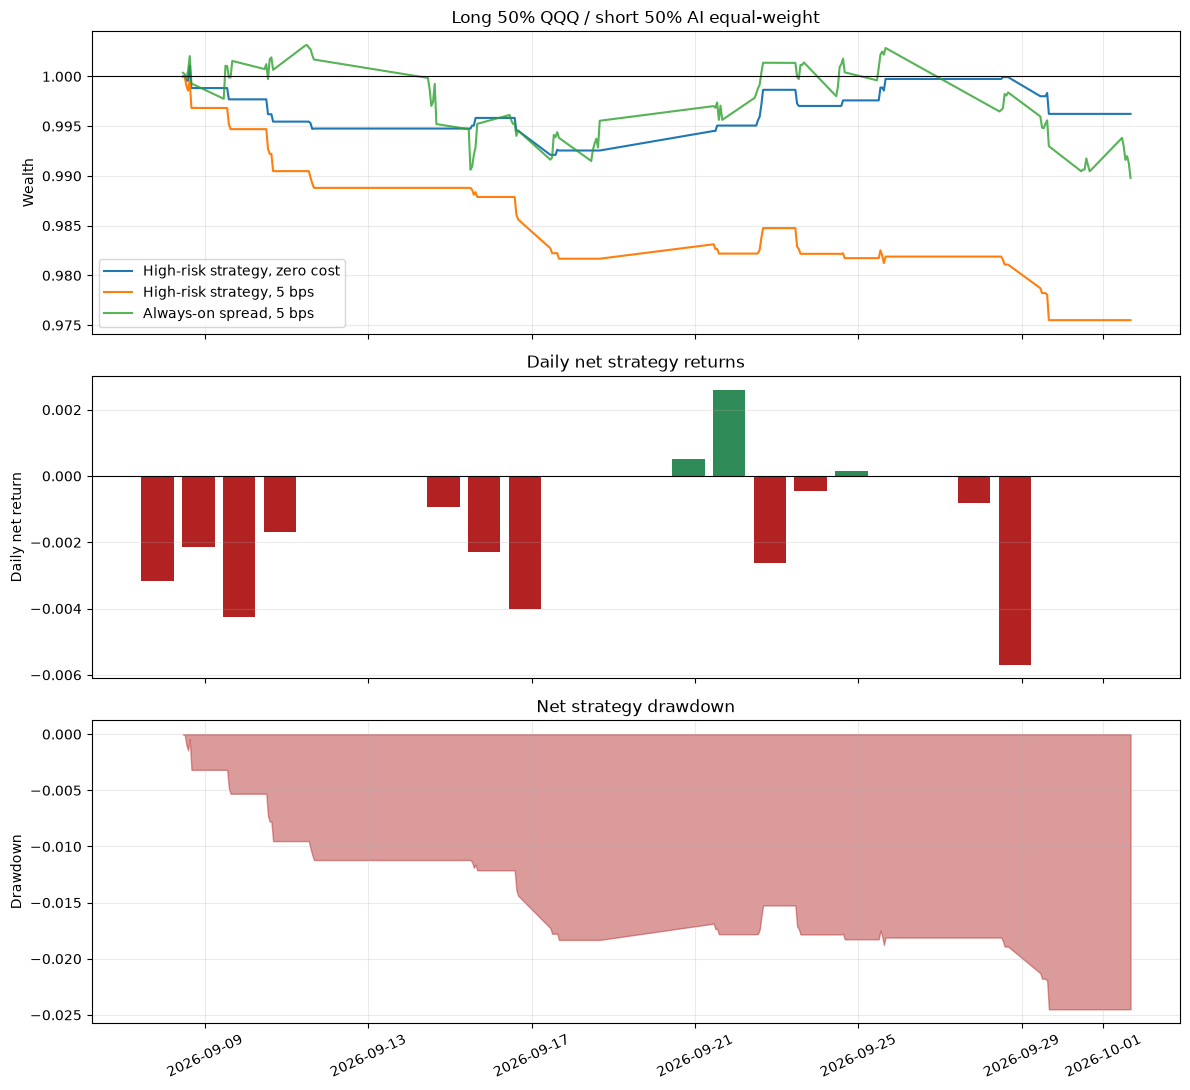

In [7]:
strategy["net_drawdown"] = strategy["net_wealth"] / strategy["net_wealth"].cummax().clip(lower=1.0) - 1.0

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
axes[0].plot(strategy["bar_end_ny"], strategy["gross_wealth"], label="High-risk strategy, zero cost")
axes[0].plot(strategy["bar_end_ny"], strategy["net_wealth"], label="High-risk strategy, 5 bps")
axes[0].plot(strategy["bar_end_ny"], strategy["always_on_net_wealth"], label="Always-on spread, 5 bps", alpha=0.8)
axes[0].axhline(1.0, color="black", lw=0.8)
axes[0].set_ylabel("Wealth")
axes[0].set_title("Long 50% QQQ / short 50% AI equal-weight")
axes[0].legend()
axes[0].grid(alpha=0.25)

daily_plot = daily.reset_index()
colors = np.where(daily_plot["net_return"].ge(0), "seagreen", "firebrick")
axes[1].bar(pd.to_datetime(daily_plot["trading_date"]), daily_plot["net_return"], color=colors)
axes[1].axhline(0.0, color="black", lw=0.8)
axes[1].set_ylabel("Daily net return")
axes[1].set_title("Daily net strategy returns")
axes[1].grid(axis="y", alpha=0.25)

axes[2].fill_between(strategy["bar_end_ny"], strategy["net_drawdown"], 0, color="firebrick", alpha=0.45)
axes[2].set_ylabel("Drawdown")
axes[2].set_title("Net strategy drawdown")
axes[2].grid(alpha=0.25)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 7. Mechanical conclusion

In [8]:
primary = performance.loc[performance["strategy"].eq("High-risk timing")].iloc[0]
active_test = diagnostics.loc[
    diagnostics["diagnostic"].eq("Mean gross long-short return in active hours")
].iloc[0]
comparison_test = diagnostics.loc[
    diagnostics["diagnostic"].eq("High-risk minus non-high spread, with hour/weekday FE")
].iloc[0]

conclusion_table = pd.DataFrame(
    {
        "metric": [
            "Threshold-available timeline hours", "Signal-ready hours",
            "High-risk active hours", "High-risk active days",
            "Gross total return (0 bps)", "Net total return (5 bps)",
            "Total modelled cost", "Maximum net drawdown", "Active-hour win rate",
            "Active-hour gross mean p-value", "High-minus-non-high spread p-value",
        ],
        "value": [
            int(primary["timeline_hours"]), int(primary["signal_ready_hours"]),
            int(primary["active_hours"]), int(primary["active_days"]),
            float(primary["gross_total_return"]), float(primary["net_total_return"]),
            float(primary["transaction_cost_sum"]), float(primary["maximum_drawdown"]),
            float(primary["active_hour_win_rate"]), float(active_test["two_sided_p"]),
            float(comparison_test["two_sided_p"]),
        ],
    }
)
display(conclusion_table)

display(
    Markdown(
        f"**结论：**在这个样本和预先设定的75%高风险阈值下，100% gross 的多空组合"
        f"费用前累计收益为 **{primary['gross_total_return']:.4%}**，加入单边5bp换手成本后为 "
        f"**{primary['net_total_return']:.4%}**。高风险持仓小时的费用前平均收益检验 "
        f"p={active_test['two_sided_p']:.4f}；控制小时和星期后，高风险相对非高风险的spread差异 "
        f"p={comparison_test['two_sided_p']:.4f}。当前数据不支持“风险高时做多QQQ、做空AI篮子能够获得正收益”；"
        "交易成本进一步明显恶化表现。"
    )
)

,metric,value
0,Threshold-available timeline hours,108
1,Signal-ready hours,100
2,High-risk active hours,31
3,High-risk active days,14
4,Gross total return (0 bps),-0.00376618
5,Net total return (5 bps),-0.0244966
6,Total modelled cost,0.0210202
7,Maximum net drawdown,-0.0244966
8,Active-hour win rate,0.516129
9,Active-hour gross mean p-value,0.63677


**结论：**在这个样本和预先设定的75%高风险阈值下，100% gross 的多空组合费用前累计收益为 **-0.3766%**，加入单边5bp换手成本后为 **-2.4497%**。高风险持仓小时的费用前平均收益检验 p=0.6368；控制小时和星期后，高风险相对非高风险的spread差异 p=0.1137。当前数据不支持“风险高时做多QQQ、做空AI篮子能够获得正收益”；交易成本进一步明显恶化表现。

## 8. Interpretation rules

1. The primary result is the 75th-percentile strategy with 5 bps one-way turnover cost. Other thresholds and cost levels are sensitivities, not alternatives chosen after seeing performance.
2. Signal thresholds use only earlier risk observations; the risk observation from `[t-1,t)` itself is not included when estimating its threshold.
3. A high-risk signal is assumed tradable at the exact start of the following hour. Real collection, scoring and order-routing latency would weaken this assumption.
4. Turnover includes drift-aware rebalancing of QQQ and all 20 short positions, plus entry, signal-driven exit and daily closing trades. Stock-borrow fees, financing and time-varying bid–ask costs remain unmodelled, so net performance is still optimistic.
5. QQQ tracks the Nasdaq-100 and differs from the Nasdaq Composite. It also contains several stocks in the AI short basket, so this is a relative basket spread rather than an independent market hedge.
6. Both QQQ and the AI stocks use Yahoo consolidated 5-minute bars aggregated to identical one-hour windows with unadjusted intraday prices; these are not guaranteed executable quotes.
7. The sample is only one month, with few trading-day clusters. Annualized Sharpe ratios are shown for scale only and should not be treated as stable estimates.
8. X News strict coverage is zero and all collection queries hit their result cap. The signal therefore represents the observed sample, not a complete news flow.